<a href="https://colab.research.google.com/github/miso-20/ESSA/blob/main/ESAA_OB_WEEK_10_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

딥러닝 파이토치 교과서 ch5. p.179~200

## 02. 합성곱 신경망 맛보기




In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.autograd import Variable
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms # 데이터 전처리를 위해 사용하는 라이브러리
from torch.utils.data import Dataset, DataLoader

In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [3]:
train_dataset = torchvision.datasets.FashionMNIST(".. /chap05/data", download=True,
                            transform=transforms.Compose([transforms.ToTensor()]))
test_dataset = torchvision.datasets.FashionMNIST(".. /chap05/data", download=True,
                            train=False, transform=transforms.Compose([transforms.ToTensor()]))

100%|██████████| 26.4M/26.4M [00:01<00:00, 14.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 211kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.94MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 25.4MB/s]


torchvision.datasets: torch.utils.data.Dataset의 하위 클래스로 다양한 데이터셋 (CIFAR, COCO, MNIST, ImageNet 등)을 포함함

torchvision.datasets에서 사용하는 주요한 파라미터는 다음과 같음
<img src="https://drive.google.com/uc?export=view&id=1OcjsMo1mRkpj9jn4mWZa7BS3LHvbbKDo" width="500">

a) 첫 번째 파라미터: FashionMNIST를 내려받을 위치를 지정함

b) download: download를 True로 변경해 주면 첫 번째 파라미터의 위치에 해당 데이터셋이 있는지 확인한 후 내려받음

c) transform: 이미지를 텐서(0~1)로 변경


In [4]:
train_loader = torch.utils.data.DataLoader(train_dataset,
                                           batch_size=100) # (1)
test_loader = torch.utils.data.DataLoader(test_dataset,
                                          batch_size=100)

(1) torch.utils.data.DataLoader()를 사용하여 원하는 크기의 배치 단위로 데이터를 불러오거나, 순서가 무작위로 섞이도록(shuffle) 할 수 있음

  데이터로더에서 사용하는 파라미터는 다음과 같음


<img src="https://drive.google.com/uc?export=view&id=1I5Azs-EScIuyo_IHpaCrB4lKnddVHH7D" width="400">

a) 첫 번째 파라미터: 데이터를 불로올 데이터셋을 지정함

b) batch_size: 데이터를 배치로 묶어 줌. 여기서는 batch_size=100으로 지정했기에 100개 단위로 데이터를 묶어서 불러옴




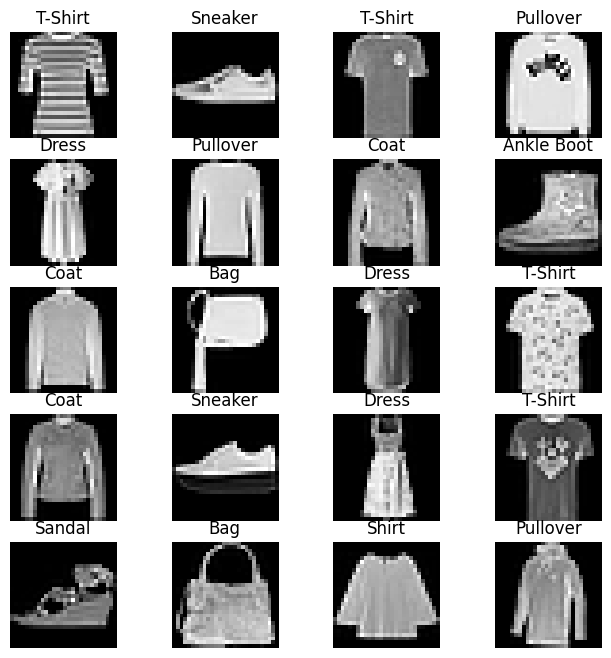

In [5]:
labels_map = {0: 'T-Shirt', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4:'Coat',
              5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle Boot'}

fig = plt.figure(figsize=(8,8));
columns = 4;
rows = 5;
for i in range(1, columns*rows +1):
    img_xy = np.random.randint(len(train_dataset));
    img = train_dataset[img_xy][0][0,:,:]
    fig.add_subplot(rows, columns, i)
    plt.title(labels_map[train_dataset[img_xy][1]])
    plt.axis('off')
    plt.imshow(img, cmap='gray')
plt.show()

np.random
- 무작위로 데이터를 생성할 때 사용

np.random.randint()
- 이산형 분포를 갖는 데이터에서 무작위 표본을 추출할 때 사용

따라서 random.randint(len(train_dataset)
- 0~(train_dataset의 길이) 값을 갖는 분포에서 랜덤한 숫자 한 개를 생성하라는 의미

In [6]:
class FashionDNN(nn.Module):
    def __init__(self):  # (1)
        super(FashionDNN, self).__init__()
        self.fc1 = nn.Linear(in_features=784, out_features=256)  # (2)
        self.drop = nn.Dropout(0.25) # (3)
        self.fc2 = nn.Linear(in_features=256, out_features=128)
        self.fc3 = nn.Linear(in_features=128, out_features=10)

    def forward(self, input_data):     # (4)
        out = input_data.view(-1, 784) # (5)
        out = F.relu(self.fc1(out))    # (6)
        out = self.drop(out)
        out = F.relu(self.fc2(out))
        out = self.fc3(out)
        return out

(1) 클래스(class) 형태의 모델은 항상 torch.nn.Module을 상속받음

__init__ (): 객체가 갖는 속성 값을 초기화하는 역할을 하며 객체가 생성될 때 자동으로 호출됨

super(FashionDNN,self).__init__(): nn.Module 클래스를 상속받겠다는 의미로 이해하면 됨


(2) nn은 딥러닝 모델(네트워크) 구성에 필요한 모듈이 모여 있는 패키지이며, Linear는 단순 선형
회귀 모델을 만들 때 사용

이때 사용되는 파라미터는 다음과 같음
<img src="https://drive.google.com/uc?export=view&id=1E389lBrmeIyTApurk8yl6EHlL-4Eg01c" width="400">

a) in_features: 입력의 크기(input size)

b) out_features: 출력의 크기(output size)

<img src="https://drive.google.com/uc?export=view&id=17wDla-rrqinDiLin_o6AenRcXcjKyYcC" width="500">



In [7]:
learning_rate = 0.001;
model = FashionDNN();
model.to(device)

criterion = nn.CrossEntropyLoss (); # 분류 문제에서 사용하는 손실 함수
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate);
print(model)

FashionDNN(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (drop): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)


In [8]:
num_epochs = 5
count = 0

loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
  for images, labels in train_loader:
      images, labels = images.to(device), labels.to(device)

      train = Variable(images.view(100, 1, 28, 28))
      labels = Variable(labels)

      outputs = model(train) # 학습 데이터를 모델에 적용
      loss = criterion(outputs, labels)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      count += 1

      if not (count % 50): # count를 50으로 나누었을 때 나머지가 0이 아니라면 실행
        total = 0
        correct = 0
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            labels_list.append(labels)
            test = Variable(images.view(100, 1, 28, 28))
            outputs = model(test)
            predictions = torch.max(outputs, 1)[1].to(device)
            predictions_list.append(predictions)
            correct += (predictions == labels).sum()
            total += len(labels)

        accuracy = correct * 100 / total
        loss_list.append(loss. data)
        iteration_list.append(count)
        accuracy_list.append(accuracy)

      if not (count % 500):
         print("Iteration: {}, Loss: {}, Accuracy: {}%" .format(count, loss.data,
                                                             accuracy))

Iteration: 500, Loss: 0.5956407785415649, Accuracy: 83.41999816894531%
Iteration: 1000, Loss: 0.4485315680503845, Accuracy: 84.81999969482422%
Iteration: 1500, Loss: 0.38886740803718567, Accuracy: 84.91999816894531%
Iteration: 2000, Loss: 0.3747406303882599, Accuracy: 85.25%
Iteration: 2500, Loss: 0.2580215334892273, Accuracy: 85.69999694824219%
Iteration: 3000, Loss: 0.3028382956981659, Accuracy: 86.90999603271484%


In [9]:
class FashionCNN(nn.Module):
    def __init__(self):
        super(FashionCNN, self).__init__()
        self.layer1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.layer2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc1 = nn.Linear(in_features=64*6*6, out_features=600)
        self.drop = nn.Dropout(0.25)
        self.fc2 = nn.Linear(in_features=600, out_features=120)
        self.fc3 = nn.Linear(in_features=120, out_features=10)

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = out.view(out.size(0), -1)
        out = self.fc1(out)
        out = self.drop(out)
        out = self.fc2(out)
        out = self.fc3(out)
        return out

**Conv2d 계층에서의 출력 크기 구하는 공식**

출력 크기 = (W-F+2P)/S+1
- W: 입력 데이터의 크기(input_volume_size)
- F: 커널 크기(kernel_size)
- P: 패딩 크기 (padding_size)
- S: 스트라이드(strides)

**MaxPool2d 계층에서의 출력 크기 구하는 공식**

출력 크기 =IF/F
- IF: 입력 필터의 크기(input_filter_size, 또한 바로 앞의 Conv2d의 출력 크기이기도 함)
- F: 커널 크기(kernel_size)



In [10]:
learning_rate = 0.001;
model = FashionCNN();
model.to(device)

criterion = nn.CrossEntropyLoss();
optimizer = torch.optim.Adam(model.parameters(), lr = learning_rate);
print(model)

FashionCNN(
  (layer1): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (layer2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc1): Linear(in_features=2304, out_features=600, bias=True)
  (drop): Dropout(p=0.25, inplace=False)
  (fc2): Linear(in_features=600, out_features=120, bias=True)
  (fc3): Linear(in_features=120, out_features=10, bias=True)
)


In [11]:
num_epochs = 5
count = 0
loss_list = []
iteration_list = []
accuracy_list = []

predictions_list = []
labels_list = []

for epoch in range(num_epochs):
  for images, labels in train_loader:
      images, labels = images.to(device), labels.to(device)

      train = Variable(images.view(100, 1, 28, 28))
      labels = Variable(labels)

      outputs = model(train)
      loss = criterion(outputs, labels)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
      count += 1

      if not (count % 50):
        total = 0
        correct = 0
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            labels_list.append(labels)
            test = Variable(images.view(100, 1, 28, 28))
            outputs = model(test)
            predictions = torch.max(outputs, 1)[1].to(device)
            predictions_list.append(predictions)
            correct += (predictions == labels).sum()
            total += len(labels)

        accuracy = correct * 100 / total
        loss_list.append(loss.data)
        iteration_list.append(count)
        accuracy_list.append(accuracy)

      if not (count % 500):
         print("Iteration: {}, Loss: {}, Accuracy: {}%" .format(count, loss.data,
                accuracy))

Iteration: 500, Loss: 0.5032066702842712, Accuracy: 88.0199966430664%
Iteration: 1000, Loss: 0.3532133400440216, Accuracy: 87.79999542236328%
Iteration: 1500, Loss: 0.29588520526885986, Accuracy: 88.45999908447266%
Iteration: 2000, Loss: 0.19395051896572113, Accuracy: 88.5199966430664%
Iteration: 2500, Loss: 0.12536557018756866, Accuracy: 89.05999755859375%
Iteration: 3000, Loss: 0.15757201611995697, Accuracy: 90.12999725341797%
